# NN_L3_fraud_by_hour

**Hourly fraud rate (weighted to the full data) over the two days of the ULB credit-card fraud data, with the start of the validation and test periods of the time-ordered split.**

Neural Networks and Deep Learning (NN), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L3/NN_L3_fraud_by_hour/NN_L3_fraud_by_hour.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Lecture 3 of *Neural Networks and Deep Learning*: the chart `fraud_by_hour` of the slides, recomputed from the public data. Numbers printed with `show()` are the ones on the slide.

fraud rate in the full data (%) = 0.173   [fraud.prev_full_pct]
highest hourly fraud rate (%) = 2.27   [fraud.rate_h_max_pct]


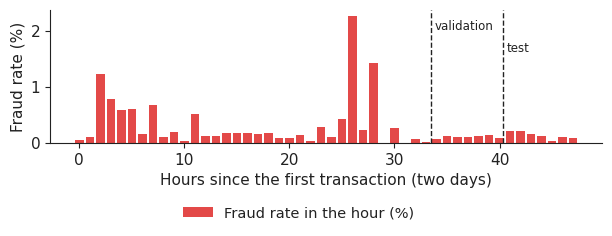

In [3]:
SEED = 20261108

fr = pd.read_csv(DATA + 'creditcard_fraud_sample.csv').sort_values('Time').reset_index(drop=True)
Xf0 = np.c_[fr[[f'V{i}' for i in range(1, 29)]].values, np.log1p(fr['Amount'].values)].astype(np.float32)
yf = fr['Class'].values.astype(int); wf = fr['weight'].values; amt = fr['Amount'].values
c1, c2 = np.quantile(fr['Time'], [0.6, 0.8])
f_tr = (fr['Time'] <= c1).values; f_va = ((fr['Time'] > c1) & (fr['Time'] <= c2)).values; f_te = (fr['Time'] > c2).values
Xf = (Xf0 - Xf0[f_tr].mean(0)) / Xf0[f_tr].std(0)
ap = lambda y, p, w: float(average_precision_score(y, p, sample_weight=w))
hour = (fr['Time'] // 3600).astype(int); rate = pd.Series(yf).groupby(hour).sum() / pd.Series(wf).groupby(hour).sum()
show('fraud.prev_full_pct', 'fraud rate in the full data (%)', round(float(100 * yf.sum() / wf.sum()), 3)); show('fraud.rate_h_max_pct', 'highest hourly fraud rate (%)', round(float(100 * rate.max()), 2))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.bar(rate.index, 100 * rate.values, color=PAL['positive'], width=0.8, label='Fraud rate in the hour (%)')
for cut, nm, y_ in ((c1, 'validation', 0.97), (c2, 'test', 0.80)):
    ax.axvline(cut / 3600, color='#222222', lw=1, ls='--'); ax.text(cut / 3600 + 0.4, y_ * 100 * rate.max(), nm, fontsize=8.5, va='top')
ax.set_xlabel('Hours since the first transaction (two days)'); ax.set_ylabel('Fraud rate (%)')
legend_bottom(fig); fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('fraud_by_hour.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()